# 51 Eri b with IFS

After this tutorial you can reduce an {term}`IFS` sequence in the YJH mode with its 39 spectral channels, check the intermediate products
that tell you whether the reduction worked, and read the position and contrast of a known
planet from the {term}`TRAP` results.

```{tutorial-stamp}
```

The page shows the products of `docs/tutorials/runs/51eri_ifs.py`, which reduced the
sequence once on a server. The cells below only read what it wrote, so you can
re-execute the page in a minute after running that script yourself (see
`docs/tutorials/runs/README.md`). The data are the {term}`IRDIFS` sequence of 51 Eri
from 2015-09-24 (programme 095.C-0298(D)), in which IFS observed in `OBS_H` while IRDIS observed in `DB_K12`.

In [ ]:
import importlib
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
from matplotlib.patches import Circle
from myst_nb import glue

sys.path[:0] = [str(Path.cwd()), str(Path.cwd() / "runs")]
from tutorial_helpers import require_run, show_log_excerpt, tutorial_dir  # noqa: E402

run = importlib.import_module("51eri_ifs")  # the run script; importing it runs nothing

%matplotlib inline
%config InlineBackend.figure_formats = ["png"]
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", "{:.4g}".format)
OBSERVATION = "reduction/IFS/observation/*_51_Eri/OBS_H/2015-09-24"
CONVERTED = f"{OBSERVATION}/optext/converted"
TRAP = "reduction/IFS/trap/*_51_Eri/OBS_H/2015-09-24"
run_dir = require_run("51eri_ifs", [
    f"{OBSERVATION}/reduction.log",
    f"{OBSERVATION}/reduction.jsonlog",
    f"{CONVERTED}/frames_info_coro.csv",
    f"{CONVERTED}/frames_info_center.csv",
    f"{CONVERTED}/image_centers_fitted_robust.fits",
    f"{CONVERTED}/psf_cube_for_postprocessing.fits",
    f"{CONVERTED}/wavelengths.fits",
    f"{TRAP}/contrast_table_ncomp038_frac0.15_temporal.csv",
    f"{TRAP}/template_matching/normalized_detection_image_T-type.fits",
    f"{TRAP}/template_matching/overall_companion_detections.csv",
    f"{TRAP}/template_matching/overall_validated_companion_detections.csv",
    f"{TRAP}/template_matching/overall_validated_companion_detections_spectra.csv",
], source_hash=run.source_hash())
converted, trap = run_dir / CONVERTED, run_dir / TRAP
wavelengths = fits.getdata(converted / "wavelengths.fits")  # nm
PIXEL_SCALE = 7.46  # mas per pixel, see Conventions

## Select the sequence

The template's `select_observations` reads the observation tables, applies the
template's quality cuts and returns the rows with the metadata the pipeline needs.
Extra keywords narrow the selection, here to one {term}`Observation sequence` by its
`OBS_ID`. IFS and IRDIS share the `OBS_ID` of an IRDIFS sequence.

In [ ]:
table, observations = run.template.select_observations(
    ["51 Eri"], database_directory=tutorial_dir() / "database", OBS_ID=run.OBS_ID)
columns = ["MAIN_ID", "NIGHT_START", "OBS_PROG_ID", "OBS_ID", "FILTER", "DEROTATOR_MODE",
           "TOTAL_EXPTIME_SCI", "ROTATION", "MEAN_FWHM", "MEAN_TAU", "HCI_READY"]
table[columns]

MAIN_ID,NIGHT_START,OBS_PROG_ID,OBS_ID,FILTER,DEROTATOR_MODE,TOTAL_EXPTIME_SCI,ROTATION,MEAN_FWHM,MEAN_TAU,HCI_READY
bytes34,bytes10,bytes14,int64,bytes6,bytes5,float64,float64,float64,float64,bool
* 51 Eri,2015-09-24,095.C-0298(D),200363269,OBS_H,PUPIL,68.267,43.216,0.754,0.006,True


The sequence lasts about 68 minutes of science exposure in {term}`Pupil tracking`,
so the sky rotates on the detector, which is what {term}`ADI` needs.

## Configure the reduction

The run script takes its configuration from
[`examples/ifs_reduction_template.py`](https://github.com/m-samland/spherical/blob/develop/examples/ifs_reduction_template.py),
the template you copy for your own targets, and changes only the directories and the
TRAP search. 51 Eri b is a known planet, so the script searches the annulus around it
and gives TRAP its position as a known companion. TRAP then keeps the planet out of the
noise model of every other position, which is how you handle any known companion.

```{literalinclude} runs/51eri_ifs.py
:language: python
:pyobject: build
```

These are the settings of the 51 Eri regression test
(`tests/regression/run_51eri_ifs_reference.py`). For a target without a known
companion, keep the template's search region and leave out the known position. The
template's two functions hold every other setting.

````{dropdown} build_config: the reduction settings
```{literalinclude} ../../examples/ifs_reduction_template.py
:language: python
:pyobject: build_config
```
````

````{dropdown} build_trap_config: the TRAP settings
```{literalinclude} ../../examples/ifs_reduction_template.py
:language: python
:pyobject: build_trap_config
```
````

## Run the reduction

The reduction runs from the command line, with the number of CPU cores to use.

```bash
python docs/tutorials/runs/51eri_ifs.py --ncpu 48
```

It downloads the raw files from the ESO archive, reduces them and runs TRAP.

In [ ]:
steps = pd.read_csv(Path.cwd().parent / "_data" / "requirements_51eri_steps.csv")
steps = steps[(steps["label"] == "51eri_ifs") & (steps["depth"] == 0)]
trap_steps = steps["step"].str.startswith("trap:")
preprocessing = steps[~trap_steps & (steps["step"] != "download_data")]["seconds"].sum() / 60
trap_minutes = steps[trap_steps]["seconds"].sum() / 60
glue("preprocessing_minutes", f"{preprocessing:.0f}", display=False)
glue("trap_minutes", f"{trap_minutes:.0f}", display=False)
glue("ncpu", int(steps["ncpu"].iloc[0]), display=False)
show_log_excerpt(run_dir / OBSERVATION / "reduction.log")

2026-10-24 17:45:20 [INFO] *_51_Eri/OBS_H/2015-09-24: Pipeline session started
2026-10-24 17:45:20 [INFO] *_51_Eri/OBS_H/2015-09-24: Start reduction of: *_51_Eri/OBS_H/2015-09-24
2026-10-24 17:45:20 [INFO] *_51_Eri/OBS_H/2015-09-24: Processing frame types: CORO, CENTER, FLUX
2026-10-24 17:45:20 [INFO] *_51_Eri/OBS_H/2015-09-24: Starting download_data_for_observation
2026-10-24 17:45:20 [INFO] *_51_Eri/OBS_H/2015-09-24: All required files already present – nothing to download.
2026-10-24 17:45:20 [INFO] *_51_Eri/OBS_H/2015-09-24: Download & sorting complete
2026-10-24 17:45:20 [INFO] *_51_Eri/OBS_H/2015-09-24: Starting update_observation_file_paths
2026-10-24 17:45:20 [INFO] *_51_Eri/OBS_H/2015-09-24: update_observation_file_paths complete
2026-10-24 17:45:20 [INFO] *_51_Eri/OBS_H/2015-09-24: Starting wavelength calibration step.
2026-10-24 17:47:06 [INFO] *_51_Eri/OBS_H/2015-09-24: Wavelength calibration completed and written to: /nexus/posix0/MIA-astro-env/thenning/msamland/data/spher

With {glue:text}`ncpu` cores the reduction took about {glue:text}`preprocessing_minutes`
minutes and TRAP about {glue:text}`trap_minutes` minutes, not counting the download.
The output above is the start and end of `reduction.log`; [Monitor runs](../how-to/monitor.md)
explains the logs, and [Practical requirements](../how-to/requirements.md) lists the time and
disk space of every step.

## Check the star centre and the rotation

TRAP needs the position of the star in every frame. The {term}`CENTER frame`s, taken with the {term}`Waffle spots` on, give the centre in each of the 39 channels. TRAP averages the CENTER frames over time and uses the result for every {term}`CORO frame`. The plot shows the centre per channel for each CENTER frame, next to the `DEROT ANGLE` of the CORO frames, which sets the field rotation.

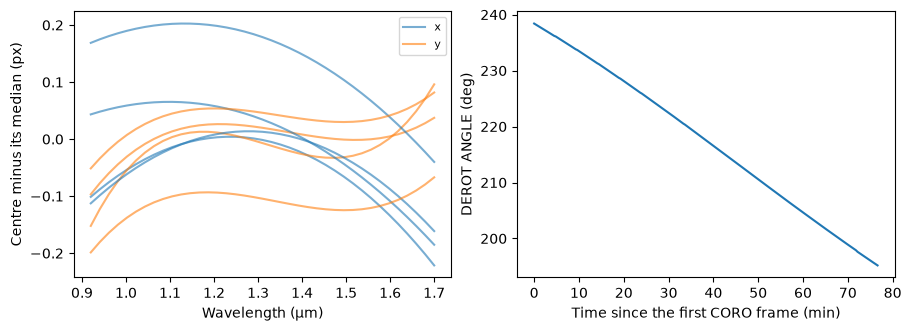

In [ ]:
frames = pd.read_csv(converted / "frames_info_coro.csv")
time = pd.to_datetime(frames["TIME"])
minutes = (time - time.iloc[0]).dt.total_seconds() / 60
centers = fits.getdata(converted / "image_centers_fitted_robust.fits")  # (channel, CENTER frame, x/y), px

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.2), layout="constrained")
microns = wavelengths / 1000
for frame in range(centers.shape[1]):
    left.plot(microns, centers[:, frame, 0] - np.nanmedian(centers[:, :, 0]), color="C0", alpha=0.6,
              label="x" if frame == 0 else None)
    left.plot(microns, centers[:, frame, 1] - np.nanmedian(centers[:, :, 1]), color="C1", alpha=0.6,
              label="y" if frame == 0 else None)
left.set_xlabel("Wavelength (µm)")
left.set_ylabel("Centre minus its median (px)")
left.legend(fontsize=8)
right.plot(minutes, frames["DEROT ANGLE"])
right.set_xlabel("Time since the first CORO frame (min)")
right.set_ylabel("DEROT ANGLE (deg)")
plt.show()
glue("rotation", f"{np.ptp(frames['DEROT ANGLE']):.1f}", display=False)
glue("n_center_frames", int(centers.shape[1]), display=False)
glue("n_nan_centres", int(np.isnan(centers).any(axis=-1).sum()), display=False)

Each line is one of the {glue:text}`n_center_frames` CENTER frames. The centre agrees between them to a fraction of a pixel in every channel, and there are {glue:text}`n_nan_centres` NaN centres. The field rotates by {glue:text}`rotation` deg.

## Check the flux PSF

The {term}`FLUX frame`s give the image of the star without coronagraph, which TRAP uses
as the model of a planet and to turn fluxes into {term}`Contrast`.
`psf_cube_for_postprocessing.fits` holds one PSF per block of FLUX frames, here the
blocks before and after the coronagraphic frames, and TRAP uses their mean.
The plot shows three of the 39 channels; the PSF grows with wavelength. The first and last channels, at the edges of the filter, are noisy, and TRAP uses channels 1 to 37 by default.

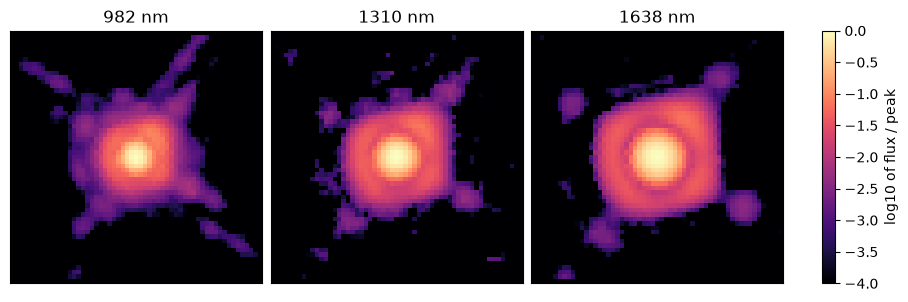

In [ ]:
psf = np.nanmean(fits.getdata(converted / "psf_cube_for_postprocessing.fits"), axis=1)
channels = [3, 19, 35]
fig, axes = plt.subplots(1, len(channels), figsize=(3.0 * len(channels), 3.0), layout="constrained")
for ax, channel in zip(np.atleast_1d(axes), channels):
    image = np.log10(np.clip(psf[channel] / np.nanmax(psf[channel]), 1e-4, None))
    shown = ax.imshow(image, origin="lower", cmap="magma", vmin=-4, vmax=0)
    ax.set_title(f"{wavelengths[channel]:.0f} nm")
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(shown, ax=axes, label="log10 of flux / peak", shrink=0.9)
plt.show()

The PSF should be a compact core with the first diffraction rings, and look the same in
all channels apart from its size. The run also logs warnings worth reading.

In [ ]:
records = []
for line in (run_dir / OBSERVATION / "reduction.jsonlog").read_text().splitlines():
    try:
        records.append(json.loads(line))
    except json.JSONDecodeError:
        continue
counts = Counter((r.get("step"), r.get("status")) for r in records if r.get("levelname") in ("WARNING", "ERROR"))
for (step, status), n in sorted(counts.items()):
    print(f"{n:3d}  {step}: {status}")

 12  flux_psf_calibration: bpm_bias_warning
 19  flux_psf_calibration: core_bpm_warning
  2  flux_psf_calibration: phase2_fallback


The warnings here come from the flux PSF step. It reports bad pixels close to the PSF
core and how much masking them changes the measured flux, repairs them with a Moffat fit or falls back to interpolation where the fit is
poor, and flags FLUX frames whose flux deviates from the rest of their block. They do not
change the result for this sequence. A `flux_saturated` or `flux_nonlinear` warning
would mean that the flux calibration, and every contrast derived from it, is not reliable.

## Read the detection map

TRAP fits a model of the planet signal at every position in the search region and gives
its significance. The {term}`Detection map` below is the one combined over the channels
with a T-type spectral template and normalised by the noise in each annulus. North is up
and east is left ([Conventions](../reference/conventions.md)). The dashed circles are
the search bounds of {glue:text}`inner` and {glue:text}`outer` pixels, and the cyan
circle marks the validated detection.

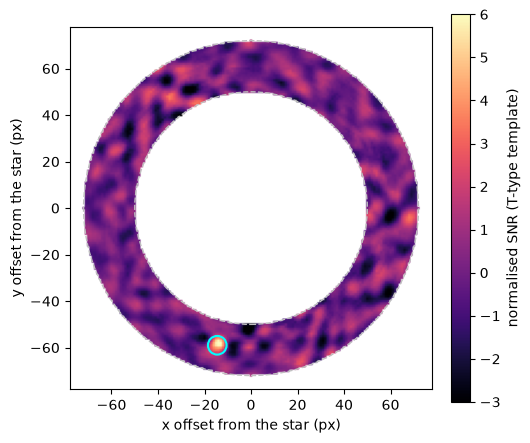

In [ ]:
snr = fits.getdata(trap / "template_matching/normalized_detection_image_T-type.fits")[0]
validated = pd.read_csv(trap / "template_matching/overall_validated_companion_detections.csv")
candidates = pd.read_csv(trap / "template_matching/overall_companion_detections.csv")
reduction = run.build(1)[1].reduction  # the TRAP settings of the run
inner, outer = reduction.search_region_inner_bound, reduction.search_region_outer_bound
cy, cx = np.array(snr.shape) // 2
extent = [-cx - 0.5, snr.shape[1] - cx - 0.5, -cy - 0.5, snr.shape[0] - cy - 0.5]

fig, ax = plt.subplots(figsize=(5.2, 4.4), layout="constrained")
shown = ax.imshow(snr, origin="lower", cmap="magma", vmin=-3, vmax=6, extent=extent)
for radius in (inner, outer):
    ax.add_patch(Circle((0, 0), radius, fill=False, color="0.75", linestyle="--"))
for _, c in validated.iterrows():
    ax.add_patch(Circle((c["x_relative"], c["y_relative"]), 4, fill=False, color="cyan", linewidth=1.5))
ax.plot(0, 0, "+", color="white")
ax.set_xlim(-outer - 6, outer + 6)
ax.set_ylim(-outer - 6, outer + 6)
ax.set_xlabel("x offset from the star (px)")
ax.set_ylabel("y offset from the star (px)")
fig.colorbar(shown, ax=ax, label="normalised SNR (T-type template)")
plt.show()
glue("inner", int(inner), display=False)
glue("outer", int(outer), display=False)
found = f"{len(candidates)} candidate" + ("s" if len(candidates) != 1 else "")
glue("candidates_sentence", f"TRAP found {found}, of which {len(validated)} passed validation.", display=False)

{glue:text}`candidates_sentence` A candidate must pass the detection threshold and a check of its shape before it is
validated.

## Contrast limits

The contrast table gives, for each separation, the spread of the noise in that annulus
after normalisation. Five times its median is the usual 5σ detection limit. The points
are 51 Eri b in the same channels.

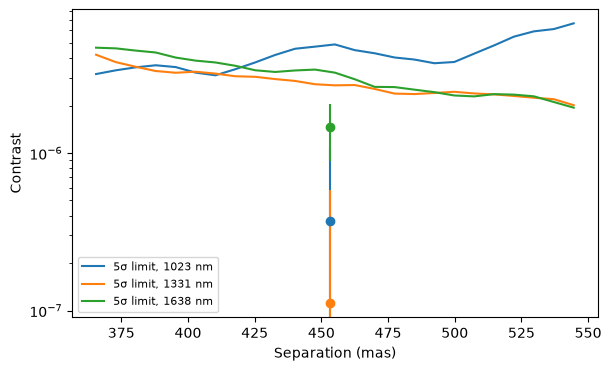

In [ ]:
limits = pd.read_csv(trap / "contrast_table_ncomp038_frac0.15_temporal.csv").dropna(subset=["contrast_50"])
spectrum = pd.read_csv(trap / "template_matching/overall_validated_companion_detections_spectra.csv")
b = validated.iloc[0]
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
for index in [5, 20, 35]:
    curve = limits[limits["wavelength_index"] == index]
    line, = ax.semilogy(curve["sep (mas)"], 5 * curve["contrast_50"], label=f"5σ limit, {wavelengths[index]:.0f} nm")
    point = spectrum[spectrum["wavelength_index"] == index]
    ax.errorbar(b["separation"] * PIXEL_SCALE, point["contrast"], yerr=point["uncertainty"], fmt="o",
                color=line.get_color())
ax.set_xlabel("Separation (mas)")
ax.set_ylabel("Contrast")
ax.legend(fontsize=8)
plt.show()

The points are 51 Eri b in three channels. Single channels are noisy at this contrast, which is why TRAP combines them through spectral templates for the detection.

## Results

The validated detection gives the position of 51 Eri b relative to the star, with
separation in pixels and in milliarcseconds and the position angle east of north.

In [ ]:
sep_mas = float(b["separation"] * PIXEL_SCALE)
sep_err_mas = float(b["separation_sigma"] * PIXEL_SCALE)
snr_b = float(max(b["norm_snr_fit_free"], b["peak_pixel_snr"]))
glue("sep_px", f"{b['separation']:.2f}", display=False)
glue("sep_mas", f"{sep_mas:.1f}", display=False)
glue("sep_err_mas", f"{sep_err_mas:.1f}", display=False)
glue("pa", f"{b['position_angle']:.2f}", display=False)
glue("pa_err", f"{b['position_angle_sigma']:.2f}", display=False)
glue("snr", f"{snr_b:.1f}", display=False)
glue("template", str(b["template_name"]), display=False)
glue("d_sep_maire", f"{sep_mas - 453.4:+.1f}", display=False)
glue("d_pa_maire", f"{b['position_angle'] - 167.15:+.2f}", display=False)

baseline = pd.read_csv(Path.cwd().parents[1] / "tests/regression/data/51eri_ifs_baseline_overall_validated_companion_detections.csv").iloc[0]
glue("d_sep_baseline", f"{b['separation'] - baseline['separation']:+.3f}", display=False)
glue("d_pa_baseline", f"{b['position_angle'] - baseline['position_angle']:+.3f}", display=False)
pd.DataFrame({
    "separation (px)": [b["separation"]], "± (px)": [b["separation_sigma"]],
    "separation (mas)": [sep_mas], "± (mas)": [sep_err_mas],
    "position angle (deg)": [b["position_angle"]], "± (deg)": [b["position_angle_sigma"]],
    "SNR": [snr_b], "template": [b["template_name"]],
})

,separation (px),± (px),separation (mas),± (mas),position angle (deg),± (deg),SNR,template
0,60.74,0.5107,453.1,3.81,166.2,0.3134,6.612,T-type


The spectrum table holds the contrast of 51 Eri b in every channel. TRAP writes wavelengths in µm, while spherical's `wavelengths.fits` is in nm. The planet shows up in the J and H bands, and between them, where water vapour absorbs, its contrast is consistent with zero.

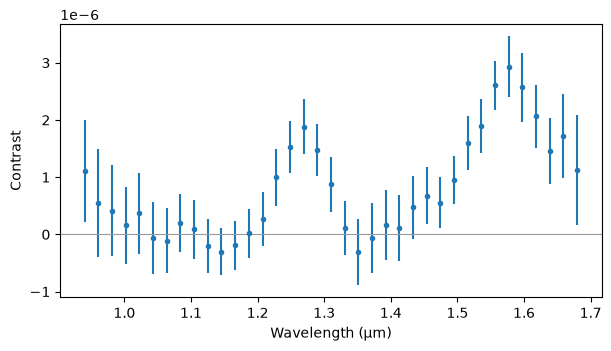

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.4), layout="constrained")
ax.errorbar(spectrum["wavelength"], spectrum["contrast"], yerr=spectrum["uncertainty"], fmt="o", markersize=3)
ax.axhline(0, color="0.6", linewidth=0.8)
ax.set_xlabel("Wavelength (µm)")
ax.set_ylabel("Contrast")
plt.show()

```{expected-result}
51 Eri b at {glue:text}`sep_px` px ({glue:text}`sep_mas` ± {glue:text}`sep_err_mas` mas),
position angle {glue:text}`pa` ± {glue:text}`pa_err` deg, SNR {glue:text}`snr`
with the {glue:text}`template` template, and no other validated candidate.
[Maire et al. (2019)](https://doi.org/10.1051/0004-6361/201935031) measured 453.4 ± 4.4 mas
and 167.15 ± 0.55 deg in K1 for this sequence; this run differs by
{glue:text}`d_sep_maire` mas and {glue:text}`d_pa_maire` deg. The 51 Eri regression test
checks the same measurement more strictly against a frozen baseline, from which this run
differs by {glue:text}`d_sep_baseline` px and {glue:text}`d_pa_baseline` deg. NaN
centres, a `flux_saturated` or `flux_nonlinear` warning, or a candidate far from the
expected position mean that something went wrong.
```

## Next

Copy [`examples/ifs_reduction_template.py`](https://github.com/m-samland/spherical/blob/develop/examples/ifs_reduction_template.py)
to reduce your own targets, and read [Output products](../concepts/products.md) for the
other files in the run. [51 Eri b with IRDIS](51eri_irdis.ipynb) reduces the same sequence with the IRDIS imager.